In [1]:
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
import pandas as pd

df = pd.read_csv(
    REPO / 'data/fogocruzado/fc_api_occurrences_with_victims_2026-08-01T12_38_31.000Z.csv',
    parse_dates=['data'],
    dayfirst=True,
)
df.head()

,id,address,region,state,city,neighborhood,sub_neighborhood,locality,latitude,longitude,...,men_dead,men_wounded,women_dead,women_wounded,kids_dead,kids_wounded,teenagers_dead,teenagers_wounded,elderly_dead,elderly_wounded
0,32868,"Rua Tonelero - Copacabana, Rio de Janeiro - RJ...",Sudeste,Rio de Janeiro,Rio de Janeiro,COPACABANA,NaN,NaN,-22.967108,-43.186172,...,0,0,0,0,0,0,0,0,0,0
1,32840,"R. Firmino Leite - Vila Dagmar, Belford Roxo -...",Sudeste,Rio de Janeiro,Belford Roxo,CENTRO,VILA DAGMAR,NaN,-22.763130,-43.403288,...,0,0,0,0,0,0,0,0,0,0
2,32841,"Antares, Santa Cruz, Rio de Janeiro - RJ, 2351...",Sudeste,Rio de Janeiro,Rio de Janeiro,SANTA CRUZ,NaN,FAVELA DE ANTARES,-22.921622,-43.663462,...,0,0,0,0,0,0,0,0,0,0
3,32850,"Venda da Cruz, Niterói - RJ, Brasil",Sudeste,Rio de Janeiro,São Gonçalo,VENDA DA CRUZ,NaN,NaN,-22.860550,-43.088999,...,0,0,0,0,0,0,0,0,0,0
4,32847,"Av. Santa Luzia - Santa Luzia, São Gonçalo - R...",Sudeste,Rio de Janeiro,São Gonçalo,SANTA LUZIA,NaN,NaN,-22.790188,-42.983825,...,0,0,0,0,0,0,0,0,0,0


In [2]:
serie_mensal = df.set_index('data').resample('ME').size()
serie_mensal.head()

data
2019-12-31      3
2020-01-31    429
2020-02-29    397
2020-03-31    447
2020-04-30    504
Freq: ME, dtype: int64

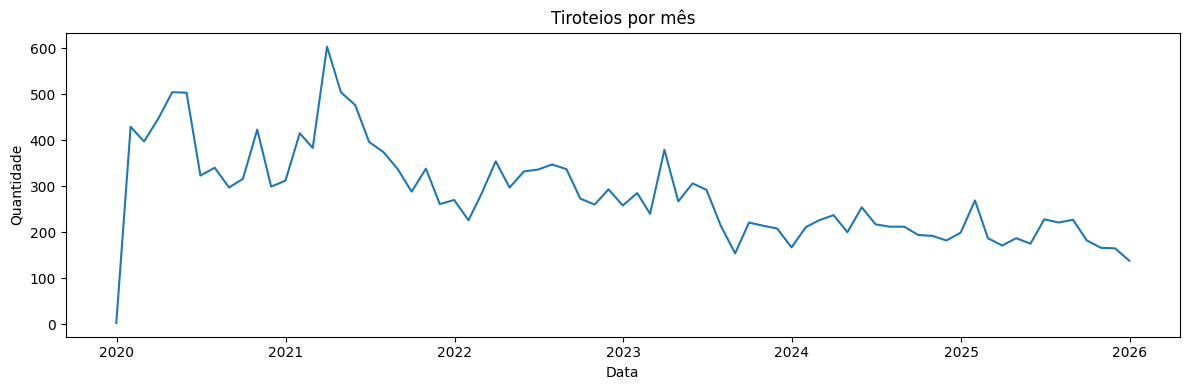

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(serie_mensal.index, serie_mensal.values, linewidth=1.5)
plt.title('Tiroteios por mês')
plt.xlabel('Data')
plt.ylabel('Quantidade')
plt.tight_layout()
plt.show()

In [4]:
from statsmodels.tsa.stattools import acf

valores = serie_mensal.values
ac = acf(valores, nlags=12, fft=False)

for lag, v in enumerate(ac):
    print(f'lag {lag:2d}: {v:+.3f}')

lag  0: +1.000
lag  1: +0.649
lag  2: +0.588
lag  3: +0.462
lag  4: +0.347
lag  5: +0.319
lag  6: +0.335
lag  7: +0.307
lag  8: +0.318
lag  9: +0.317
lag 10: +0.325
lag 11: +0.404
lag 12: +0.450


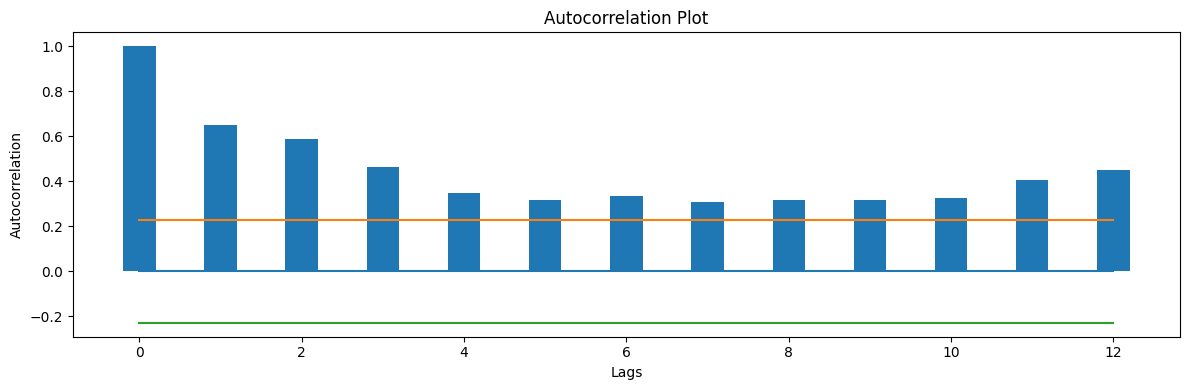

In [5]:
import numpy as np

values = ac        # autocorrelações calculadas na célula anterior
lags = len(ac)
data = valores

plt.figure(figsize=(12, 4))
plt.plot(np.zeros_like(values))
plt.plot(np.ones_like(values) * 1.96 * (1 / np.sqrt(len(data))))
plt.plot(np.ones_like(values) * (-1.96) * (1 / np.sqrt(len(data))))
plt.bar(range(lags), values, width=0.4)
plt.title('Autocorrelation Plot')
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.tight_layout()
plt.show()

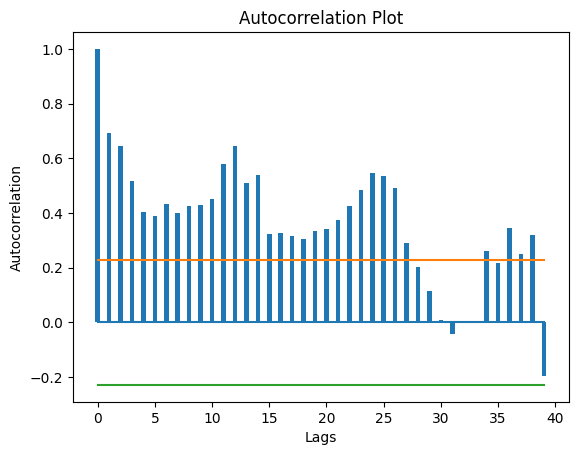

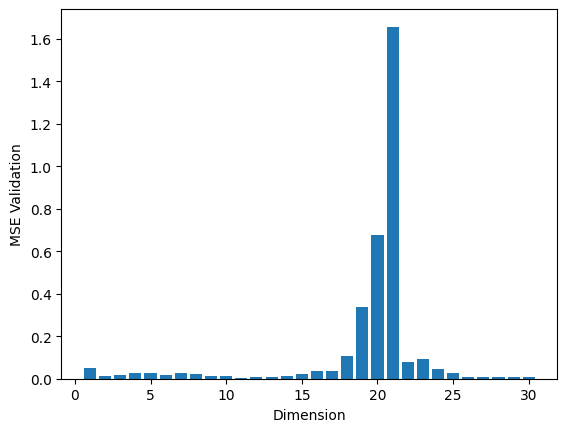

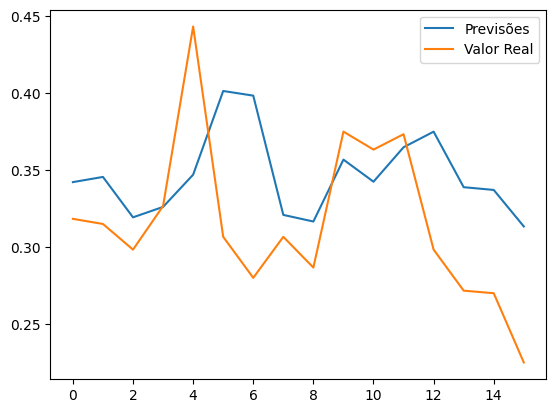

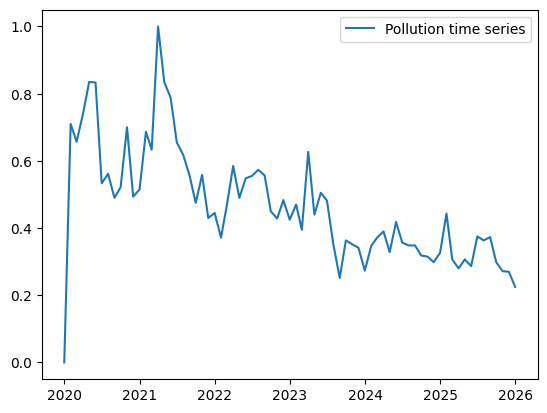

In [6]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error as mse
from matplotlib import pyplot as plt


def acf_plot(data,lags):
    values=[]
    for i in range((lags)):
        values.append(data.autocorr(i))

    plt.plot(np.zeros_like(values))
    plt.plot(np.ones_like(values)*1.96*(1/np.sqrt(len(data))))
    plt.plot(np.ones_like(values)*(-1.96)*(1/np.sqrt(len(data))))
    plt.bar(range(lags),values,width=0.4)
    plt.title('Autocorrelation Plot')
    plt.xlabel('Lags')
    plt.ylabel('Autocorrelation')
    plt.show()

trainSplit = 0.6 # Usado para treinar o modelo
validSplit= 0.2  #Verificar se o modelo é adequado



dataset = serie_mensal.drop(columns=['data'])



trainSize = int(np.floor(trainSplit*len(dataset)))
validSize = int(np.floor(validSplit*len(dataset)))

maxData = np.max(dataset[0:trainSize])
minData = np.min(dataset[0:trainSize])

ndataset  = (dataset  - minData)/(maxData-minData)


datasetSeries = pd.Series(ndataset)
acf_plot(datasetSeries,40)
dimension = 30
stepahead = 1





bestValue = 10**10
model=0
erroBar = []

for dim in range(1,dimension+1,1):

    datasetShifted = pd.concat([datasetSeries.shift(i) for i in range(dim+stepahead) ],axis=1)
    train = (datasetShifted.iloc[dim:trainSize,1:])
    train = np.hstack((train,np.ones_like(train.iloc[:,0].values.reshape(len(train),1))))
    trainTarget = (datasetShifted.iloc[dim:trainSize,0])

    valid = datasetShifted.iloc[trainSize:(validSize+trainSize),1:]
    valid=np.hstack((valid,np.zeros_like(valid.iloc[:,0].values.reshape(len(valid),1))))
    validTarget = datasetShifted.iloc[trainSize:(validSize+trainSize),0]

    test = datasetShifted.iloc[(validSize+trainSize):,1:]
    test= np.hstack((test,np.ones_like(test.iloc[:,0].values.reshape(len(test),1))))
    testTarget = datasetShifted.iloc[(validSize+trainSize):,0]


    X_inv = np.linalg.pinv(train)
    coefs = X_inv.dot(trainTarget)

    predVal = coefs.dot(valid.T)
    erro = mse(predVal,validTarget)

    erroBar.append(erro)
    if(erro<bestValue):
        bestValue=erro
        model=coefs
        test_aux = test
        testTarget_aux = testTarget


plt.bar(range(1,dimension+1,1),erroBar)
plt.xlabel('Dimension')
plt.ylabel('MSE Validation')
plt.show()




predTest = model.dot(test_aux.T)

mse_test = mse(predTest,testTarget_aux)

plt.plot(predTest)
plt.plot(testTarget_aux.values)
plt.legend(['Previsões','Valor Real'])
plt.show()

plt.plot(datasetSeries)
plt.legend(['Pollution time series'])
plt.show()

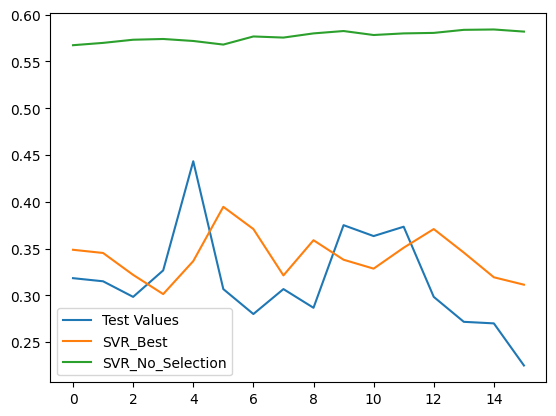

In [7]:
import numpy as np
import pandas as pd
from sklearn.svm import SVR # support vector regression
from sklearn.metrics import mean_squared_error as mse
from matplotlib import pyplot as plt
trainSplit = 0.6
validSplit= 0.2


dataset = serie_mensal.drop(columns=['data'])
trainSize = int(np.floor(trainSplit*len(dataset)))
validSize = int(np.floor(validSplit*len(dataset)))

maxData = np.max(dataset[0:trainSize])
minData = np.min(dataset[0:trainSize])

ndataset  = (dataset  - minData)/(maxData-minData)


datasetSeries = pd.Series(ndataset)
dimension = 12
stepahead = 1
datasetShifted = pd.concat([datasetSeries.shift(i) for i in range(dimension+stepahead) ],axis=1)

train = (datasetShifted.iloc[dimension:trainSize,1:])
trainTarget = (datasetShifted.iloc[dimension:trainSize,0])

valid = datasetShifted.iloc[trainSize:(validSize+trainSize),1:]
validTarget = datasetShifted.iloc[trainSize:(validSize+trainSize),0]

test = datasetShifted.iloc[(validSize+trainSize):,1:]
testTarget = datasetShifted.iloc[(validSize+trainSize):,0]



g=(10.0)**np.arange(-5,3,1) #10
e = (10.0)**np.arange(-4,-1,1) # 10
c=(10.0)**np.arange(-2,3,1)#10
bestValue = 10**100000
erroval = []
param=[]
bestSVR=0
for i in g:
    for j in e:
        for k in c:

            mySVR = SVR(C=k,gamma=i,epsilon=j)
            mySVR.fit(train,trainTarget)

            predVals = mySVR.predict(valid)
            erro = mse(predVals,validTarget)
            erroval.append(erro)
            param.append((i,j,k))
            if erro<bestValue:
                bestValue=erro
                bestSVR = mySVR


predTest = bestSVR.predict(test)
mseTest = mse(predTest,testTarget)

SVR_no_Selection = SVR()
SVR_no_Selection.fit(train,trainTarget)
predTestNoSelection = SVR_no_Selection.predict(test)

mseTest_noSelection = mse(predTestNoSelection,testTarget)







plt.plot(testTarget.values)
plt.plot(predTest)
plt.plot(predTestNoSelection)
#plt.plot(predSVRGridCV)
plt.legend(['Test Values','SVR_Best','SVR_No_Selection'])

In [8]:
import numpy as np
import pandas as pd
from sklearn.svm import SVR # support vector regression
from sklearn.metrics import mean_squared_error as mse
from matplotlib import pyplot as plt
trainSplit = 0.6
validSplit= 0.2

dataset = serie_mensal.drop(columns=['data']).replace('NaN', np.nan).dropna()
trainSize = int(np.floor(trainSplit*len(dataset)))
validSize = int(np.floor(validSplit*len(dataset)))

maxData = np.max(dataset)
minData = np.min(dataset)

ndataset  = (dataset  - minData)/(maxData-minData)


datasetSeries = pd.Series(ndataset)
dimension = 12
stepahead = 2

datasetShifted = pd.concat([datasetSeries.shift(i) for i in range(dimension+stepahead) ],axis=1).dropna().drop(columns=[13])

train = (datasetShifted.iloc[dimension:trainSize,1:])
trainTarget = (datasetShifted.iloc[dimension:trainSize,0])

valid = datasetShifted.iloc[trainSize:(validSize+trainSize),1:]
validTarget = datasetShifted.iloc[trainSize:(validSize+trainSize),0]

test = datasetShifted.iloc[(validSize+trainSize):,1:]
testTarget = datasetShifted.iloc[(validSize+trainSize):,0]



g=(10.0)**np.arange(-5,3,1) #10
e = (10.0)**np.arange(-4,-1,1) # 10
c=(10.0)**np.arange(-2,3,1)#10
bestValue = 10**100000
erroval = []
param=[]
bestSVR=0
for i in g:
    for j in e:
        for k in c:

            mySVR = SVR(C=k,gamma=i,epsilon=j)
            mySVR.fit(train,trainTarget)

            predVals = mySVR.predict(valid)
            erro = mse(predVals,validTarget)
            erroval.append(erro)
            param.append((i,j,k))
            if erro<bestValue:
                bestValue=erro
                bestSVR = mySVR

# pred_test = bestSVR.predict(test)

# last_value = testTarget.iloc[-1]
# last_window = test.iloc[-1,:].tolist()


# window = []
# window.append(last_value)
# window.extend(last_window[:dimension-1])


# day_30_prediction = bestSVR.predict(np.array(window).reshape(1,-1))
# day_30_prediction = (day_30_prediction[0]*(maxData-minData))+minData



In [9]:
datasetShifted = datasetShifted.drop(columns=[12])

In [21]:
datasetShifted

,0,1,2,3,4,5,6,7,8,9,10,11
data,,,,,,,,,,,,
2021-01-31,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.656667
2021-02-28,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000
2021-03-31,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000
2021-04-30,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333
2021-05-31,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333
2021-06-30,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667
2021-07-31,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000
2021-08-31,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667
2021-09-30,0.475000,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000


In [10]:
SVR_dataset = datasetShifted.copy()

In [11]:
SVR_dataset['z1'] = bestSVR.predict(SVR_dataset.iloc[:, :12].to_numpy())
SVR_dataset['z2'] = bestSVR.predict(SVR_dataset.iloc[:, [12] + list(range(0, 11))].to_numpy())
SVR_dataset['z3'] = bestSVR.predict(SVR_dataset.iloc[:, [13] + list(range(0, 11))].to_numpy())
SVR_dataset['z4'] = bestSVR.predict(SVR_dataset.iloc[:, [14] + list(range(0, 11))].to_numpy())
SVR_dataset['z5'] = bestSVR.predict(SVR_dataset.iloc[:, [15] + list(range(0, 11))].to_numpy())

In [22]:
SVR_dataset

,0,1,2,3,4,5,6,7,8,9,10,11,z1,z2,z3,z4,z5
data,,,,,,,,,,,,,,,,,
2021-01-31,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.656667,0.495780,0.515777,0.516734,0.516777,0.516779
2021-02-28,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.520230,0.507155,0.506491,0.506457,0.506455
2021-03-31,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.501841,0.507536,0.507797,0.507809,0.507810
2021-04-30,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.509444,0.491646,0.490780,0.490736,0.490734
2021-05-31,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.496336,0.479500,0.478724,0.478687,0.478686
2021-06-30,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.484287,0.465101,0.464152,0.464104,0.464102
2021-07-31,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.470184,0.446866,0.445763,0.445709,0.445707
2021-08-31,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.450444,0.437381,0.436721,0.436687,0.436685
2021-09-30,0.475000,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.438585,0.418186,0.417124,0.417068,0.417066


In [13]:
from sklearn.neural_network import MLPRegressor

MLP = MLPRegressor()
MLP.fit(train,trainTarget)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [14]:
MLP_dataset = datasetShifted.copy()

MLP_dataset['z1'] = MLP.predict(MLP_dataset.iloc[:, :12].to_numpy())
MLP_dataset['z2'] = MLP.predict(MLP_dataset.iloc[:, [12] + list(range(0, 11))].to_numpy())
MLP_dataset['z3'] = MLP.predict(MLP_dataset.iloc[:, [13] + list(range(0, 11))].to_numpy())
MLP_dataset['z4'] = MLP.predict(MLP_dataset.iloc[:, [14] + list(range(0, 11))].to_numpy())
MLP_dataset['z5'] = MLP.predict(MLP_dataset.iloc[:, [15] + list(range(0, 11))].to_numpy())

In [15]:
MLP_dataset

,0,1,2,3,4,5,6,7,8,9,10,11,z1,z2,z3,z4,z5
data,,,,,,,,,,,,,,,,,
2021-01-31,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.656667,0.671989,0.566923,0.562394,0.562199,0.562190
2021-02-28,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.565257,0.679622,0.687399,0.687926,0.687955
2021-03-31,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.707553,0.650311,0.646936,0.646737,0.646725
2021-04-30,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.657825,0.462508,0.444683,0.442788,0.442587
2021-05-31,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.474021,0.568973,0.575381,0.575814,0.575843
2021-06-30,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.581187,0.427230,0.420506,0.420287,0.420280
2021-07-31,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.428938,0.517403,0.519679,0.519751,0.519753
2021-08-31,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.521199,0.615948,0.620458,0.620672,0.620683
2021-09-30,0.475000,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.613749,0.575315,0.574127,0.574090,0.574089


In [16]:
from sklearn.ensemble import RandomForestRegressor

RF = RandomForestRegressor()
RF.fit(train, trainTarget)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [17]:
RF_dataset = datasetShifted.copy()

RF_dataset['z1'] = RF.predict(RF_dataset.iloc[:, :12].to_numpy())
RF_dataset['z2'] = RF.predict(RF_dataset.iloc[:, [12] + list(range(0, 11))].to_numpy())
RF_dataset['z3'] = RF.predict(RF_dataset.iloc[:, [13] + list(range(0, 11))].to_numpy())
RF_dataset['z4'] = RF.predict(RF_dataset.iloc[:, [14] + list(range(0, 11))].to_numpy())
RF_dataset['z5'] = RF.predict(RF_dataset.iloc[:, [15] + list(range(0, 11))].to_numpy())

In [18]:
RF_dataset

,0,1,2,3,4,5,6,7,8,9,10,11,z1,z2,z3,z4,z5
data,,,,,,,,,,,,,,,,,
2021-01-31,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.656667,0.516317,0.505517,0.503833,0.503833,0.503833
2021-02-28,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.740000,0.506367,0.499833,0.499833,0.499833,0.499833
2021-03-31,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.835000,0.500900,0.508617,0.508617,0.508617,0.508617
2021-04-30,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.833333,0.509383,0.446433,0.437100,0.439717,0.438283
2021-05-31,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.533333,0.451050,0.458050,0.458783,0.457533,0.458783
2021-06-30,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.561667,0.470567,0.460567,0.461083,0.461083,0.461083
2021-07-31,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.490000,0.473933,0.429633,0.434900,0.434900,0.434900
2021-08-31,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.521667,0.443850,0.458383,0.460417,0.460417,0.460417
2021-09-30,0.475000,0.556667,0.618333,0.655000,0.788333,0.835000,1.000000,0.633333,0.686667,0.515000,0.493333,0.700000,0.459300,0.461867,0.460950,0.461867,0.460950


   Modelo Previsão  Horizonte       MSE    MAP (%)       MAE
0      RF       z1          1  0.010750  12.644634  0.059783
1      RF       z2          2  0.011003  12.843243  0.059792
2      RF       z3          3  0.009140  16.226190  0.068985
3      RF       z4          4  0.006673  14.824591  0.058657
4      RF       z5          5  0.006858  16.946641  0.065284
5     MLP       z1          1  0.015042  24.591316  0.097569
6     MLP       z2          2  0.016204  25.891618  0.102294
7     MLP       z3          3  0.013603  25.285109  0.094238
8     MLP       z4          4  0.013658  27.173652  0.101297
9     MLP       z5          5  0.012970  26.860376  0.096990
10    SVR       z1          1  0.011784  14.112903  0.067278
11    SVR       z2          2  0.011934  14.546601  0.068335
12    SVR       z3          3  0.008121  14.261778  0.061842
13    SVR       z4          4  0.006352  14.117100  0.058161
14    SVR       z5          5  0.005326  14.395158  0.056567


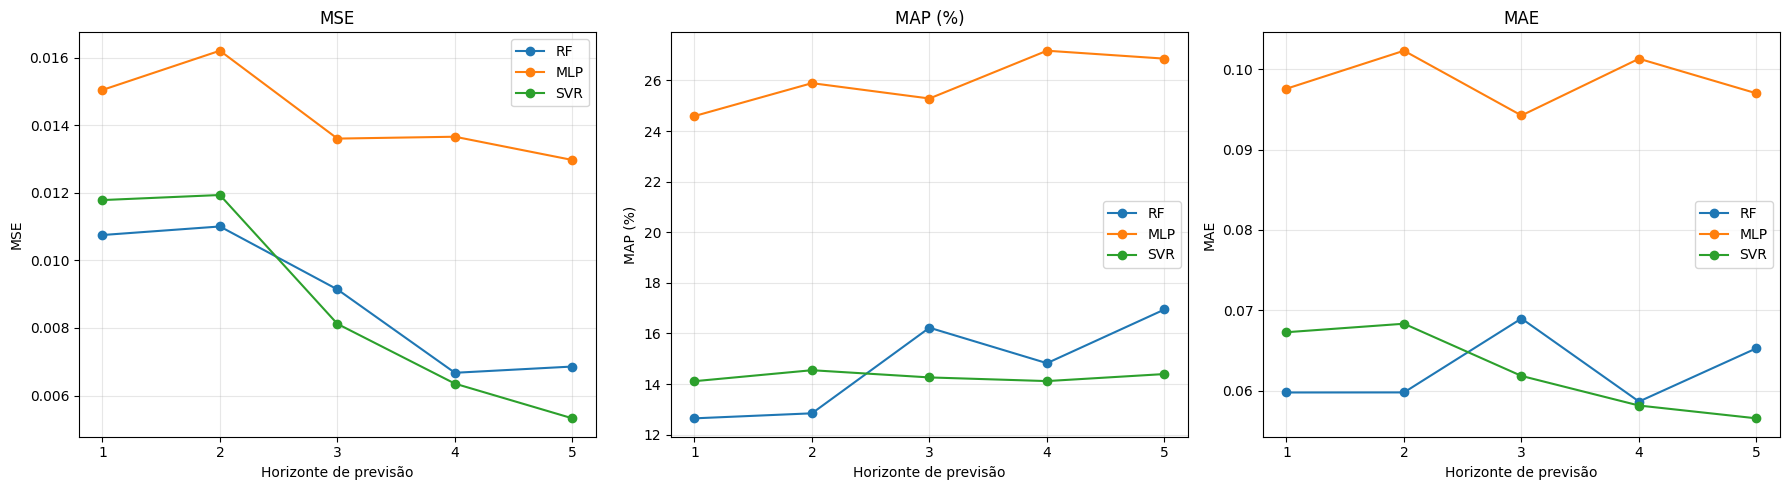

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

datasets = {
    "RF": RF_dataset,
    "MLP": MLP_dataset,
    "SVR": SVR_dataset,
}

resultados = []

for modelo, df in datasets.items():
    for horizonte in range(1, 6):
        previsao = f"z{horizonte}"
        y_true = df[0].shift(-horizonte)
        y_pred = df[previsao]

        dados = pd.DataFrame({
            "real": y_true,
            "previsto": y_pred
        }).dropna()

        mse = mean_squared_error(dados["real"], dados["previsto"])
        mae = mean_absolute_error(dados["real"], dados["previsto"])

        validos = dados["real"] != 0
        map_ = (
            np.mean(
                np.abs(
                    (dados.loc[validos, "real"] - dados.loc[validos, "previsto"])
                    / dados.loc[validos, "real"]
                )
            ) * 100
        )

        resultados.append({
            "Modelo": modelo,
            "Previsão": previsao,
            "Horizonte": horizonte,
            "MSE": mse,
            "MAP (%)": map_,
            "MAE": mae
        })

resultado_final = pd.DataFrame(resultados)
print(resultado_final)

metricas = ["MSE", "MAP (%)", "MAE"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metrica in zip(axes, metricas):
    for modelo in datasets:
        dados_modelo = resultado_final[resultado_final["Modelo"] == modelo]
        ax.plot(
            dados_modelo["Horizonte"],
            dados_modelo[metrica],
            marker="o",
            label=modelo
        )

    ax.set_title(metrica)
    ax.set_xlabel("Horizonte de previsão")
    ax.set_ylabel(metrica)
    ax.set_xticks(range(1, 6))
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

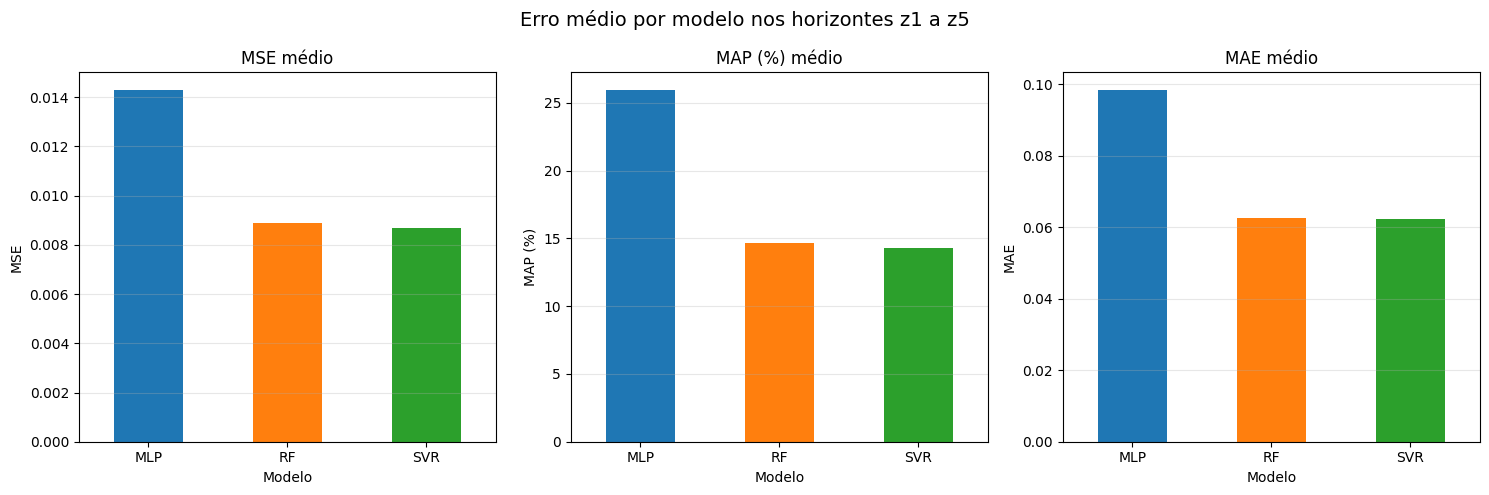

,MSE,MAP (%),MAE
Modelo,,,
MLP,0.014296,25.960414,0.098477
RF,0.008885,14.697060,0.062500
SVR,0.008703,14.286708,0.062437


In [20]:
medias = resultado_final.groupby("Modelo")[["MSE", "MAP (%)", "MAE"]].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metrica in zip(axes, medias.columns):
    medias[metrica].plot(
        kind="bar",
        ax=ax,
        color=["#1f77b4", "#ff7f0e", "#2ca02c"]
    )
    ax.set_title(f"{metrica} médio")
    ax.set_xlabel("Modelo")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Erro médio por modelo nos horizontes z1 a z5", fontsize=14)
plt.tight_layout()
plt.show()

medias